# Compare biological conditions across donors

This page tests whether gamma-delta T cells from people with rheumatoid arthritis (RA) express six interferon-response, cytokine, cytotoxicity, and effector-memory genes differently from those of matched controls. The data are human peripheral blood mononuclear cells (PBMCs) from the Binvignat cohort, in which 18 RA donors are each matched to a control donor and the samples were sequenced in three batches [@Binvignat_2024]. The page selects 1,386 gamma-delta T cells of these 36 donors from 108,717 cells, tests the six genes with a paired Wilcoxon signed-rank test on donor means, and then sums each donor's raw counts into a pseudobulk profile and exports the profiles, with the paired design, for a genome-wide count model such as DESeq2 or edgeR.

No gene differs significantly between the conditions: the smallest p-value, 0.14 for ISG15, becomes 0.69 after correction for the six tests. For S100A4, GZMA, and ISG15, batch 3 holds the highest donor means and the largest within-pair differences, so its pairs weigh most in the tests of these genes. In most batch-3 pairs, S100A4 and GZMA are lower in the RA donor. For the count model, requiring 20 gamma-delta T cells from both donors of a pair keeps 8 of the 18 pairs, only 2 of them from batch 3.

Both analyses treat the donor, not the cell, as the replicate. Cells from one person share that person's genotype, disease activity, treatment, and sample handling, so the 1,386 cells are not 1,386 independent observations. A test that counted cells as replicates would mistake differences between individual donors for an effect of disease and report p-values far smaller than 36 donors can support, an error called pseudoreplication.

## Prepare the source data

The code downloads the published H5AD file once, checks that `raw/X` has the published numbers of cells and genes and that its sampled values are whole counts, converts the counts to a local Zarr store within a 6 GiB memory budget, and mounts that store: selections and test results then go to a temporary analysis store, while the counts stay in the reusable source. The first run needs network access; later runs reuse both files. [](batch_correction.ipynb) describes the dataset and its three sequencing batches, and uses the same files.

In [1]:
# Load the tools for downloading, converting, and comparing the data.
from os import environ
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy.stats import wilcoxon

import cytearc
from cytearc.plotting import CellField, StudyDesign

# Print warnings and errors only, without progress bars.
cytearc.configure_output(level="WARNING", progress=False)

# Keep the download and the converted store in a folder that later sessions reuse.
dataset_directory = Path(environ.get("CYTEARC_DOCS_DATA_DIR", "cytearc_datasets"))
dataset_directory.mkdir(parents=True, exist_ok=True)
h5ad_path = dataset_directory / "binvignat_ra_pbmc.h5ad"
source_store = dataset_directory / "binvignat_ra_pbmc.zarr"

Started: 2026-11-12T17:12:01.769400Z | Wall time: 3.504 s

In [2]:
# Download the versioned H5AD file once, under a temporary name until it is complete.
if not h5ad_path.exists():
    partial_path = h5ad_path.with_suffix(".h5ad.part")
    urlretrieve(
        "https://datasets.cellxgene.cziscience.com/3b751975-34bb-409a-a9b7-98380f0450ea.h5ad",
        partial_path,
    )
    partial_path.replace(h5ad_path)

# Check that raw/X has the published cells and genes, and that its sampled values are whole counts.
inspection = cytearc.inspect_h5ad(str(h5ad_path))
assert inspection.matrixKey == "raw/X"
assert inspection.integerLike is True
assert (inspection.nCells, inspection.nFeatures) == (108_717, 21_648)
{
    "count matrix": inspection.matrixKey,
    "cells": inspection.nCells,
    "genes": inspection.nFeatures,
    "integer counts": inspection.integerLike,
}

{'count matrix': 'raw/X',
 'cells': 108717,
 'genes': 21648,
 'integer counts': True}

Started: 2026-11-12T17:12:05.279908Z | Wall time: 1.856 s

In [3]:
# Convert the counts once, in a temporary folder until the store is complete.
if not source_store.exists():
    with TemporaryDirectory(dir=dataset_directory) as conversion_directory:
        staged_store = Path(conversion_directory) / source_store.name
        reader = cytearc.H5adReader.from_inspect(inspection)
        try:
            cytearc.H5adToZarr(
                reader,
                zarr_loc=str(staged_store),
                assay_name="RNA",
                nthreads=4,
                mem_budget="6G",
            ).dump()
        finally:
            reader.h5.close()
        staged_store.replace(source_store)

Started: 2026-11-12T17:12:07.138544Z | Wall time: 21.043 s

In [4]:
# Open the converted store once, which prepares it for mounting and keeps every cell with counts.
source = cytearc.DataStore(
    str(source_store), default_assay="RNA", min_features_per_cell=0, nthreads=4
)

# Mount it: counts stay in the source, and selections and test results go to a temporary analysis store.
analysis_directory = TemporaryDirectory()
ds = cytearc.mount_datastore(
    str(source_store),
    at=str(Path(analysis_directory.name) / "ra_condition_comparisons.zarr"),
    default_assay="RNA",
    min_features_per_cell=0,
    nthreads=4,
)
{"cells": ds.cells.N, "genes": ds.RNA.feats.N}

{'cells': 108717, 'genes': 21648}

Started: 2026-11-12T17:12:28.186265Z | Wall time: 4.235 s

## Select gamma-delta T cells from matched pairs

The publication labels gamma-delta T cells `yd T cells` in `fine_annot` and numbers the matched RA-control pairs in `pair_index_CW`. The selection keeps the gamma-delta T cells that carry a pair number, and `snapshot_cell_selection` freezes them, returning a reference to an immutable record of exactly these cells. The test, the donor means, and the pseudobulk below all read that reference, so every result describes the same cells. The donor design keeps one row per donor with its condition, pair, and batch, and every pair must hold one control and one RA donor.

In [5]:
# Read each cell's type, donor, condition, matched pair, and sequencing batch.
cell_metadata = pd.DataFrame(
    {
        column: ds.cells.fetch_all(column)
        for column in ("fine_annot", "donor_id", "disease", "pair_index_CW", "batch")
    }
)

# Keep the gamma-delta T cells that carry a pair number, and freeze them as a cell selection.
gamma_delta = cell_metadata["fine_annot"].eq("yd T cells")
has_pair = np.isfinite(cell_metadata["pair_index_CW"].astype(float))
matched_gamma_delta = gamma_delta & has_pair
ds.cells.insert("matched_yd_t_cells", matched_gamma_delta.to_numpy(), overwrite=True)
cells = ds.snapshot_cell_selection("matched_yd_t_cells")

# Check that the gamma-delta T cells left out are the bridging donor's cells from batches 2 and 3.
unpaired = cell_metadata[gamma_delta & ~has_pair]
assert set(unpaired["donor_id"]) == {"Control07_1_C_F"}
assert set(unpaired["batch"].astype(str)) == {"2", "3"}

# Reduce the selected cells to one design row per donor, which needs one condition, pair, and batch per donor.
selected_cells = cell_metadata.loc[
    matched_gamma_delta, ["donor_id", "disease", "pair_index_CW", "batch"]
]
assert selected_cells.groupby("donor_id").nunique().eq(1).all().all()
donor_design = (
    selected_cells.drop_duplicates()
    .set_index("donor_id")
    .astype({"pair_index_CW": int})
    .sort_values(["pair_index_CW", "disease"])
)

# Require one control and one rheumatoid arthritis donor in every pair.
GROUPS = ["normal", "rheumatoid arthritis"]
pair_conditions = donor_design.groupby("pair_index_CW")["disease"].agg(
    ["size", "nunique"]
)
assert pair_conditions.eq(2).all().all() and set(donor_design["disease"]) == set(GROUPS)
pd.Series(
    {
        "gamma-delta T cells": int(gamma_delta.sum()),
        "without a pair number": len(unpaired),
        "selected cells": int(matched_gamma_delta.sum()),
        "donors": len(donor_design),
        "matched pairs": len(pair_conditions),
    }
)

gamma-delta T cells      1424
without a pair number      38
selected cells           1386
donors                     36
matched pairs              18
dtype: int64

Started: 2026-11-12T17:12:32.425203Z | Wall time: 0.195 s

Of the 1,424 gamma-delta T cells, 1,386 carry a pair number. The other 38 belong to Control07_1_C_F, the control of pair 7 and the donor that [](batch_correction.ipynb) follows through all three sequencing batches: only its batch-1 cells carry the pair number, so every donor enters the comparison from one batch. The 36 donors form 18 pairs, so the tests below have at most 18 replicates, one per pair. In every pair but one, both donors were sequenced in the same batch:

In [6]:
# Find the pairs whose two donors were sequenced in different batches.
batches_per_pair = donor_design.groupby("pair_index_CW")["batch"].nunique()
donor_design[
    donor_design["pair_index_CW"].isin(batches_per_pair.index[batches_per_pair > 1])
]

,disease,pair_index_CW,batch
donor_id,,,
Control16_1_C_F,normal,22,2
RA22_1_C_F,rheumatoid arthritis,22,3


Started: 2026-11-12T17:12:32.623356Z | Wall time: 0.019 s

Pair 22 matches a control from batch 2 with an RA donor from batch 3, so its difference mixes disease with batch, and the paired test has no batch term to separate them.

## Test six genes on paired donor means

The six genes cover effector cytokines (IFNG, TNF), interferon-stimulated genes (IFIT2, ISG15), the cytotoxic protease granzyme A (GZMA), and S100A4, a calcium-binding protein of effector and memory T cells. `CellField("disease")` names the cell column that holds the conditions, and `groups` picks the two conditions and their order. `StudyDesign` names the column that identifies donors (`sample_by`) and the column that matches them in pairs (`pair_by`). With these, `compare.test` scales each cell's counts to 1,000 in total, averages each gene over each donor's cells, takes the difference between the two donors of each pair, and runs a two-sided Wilcoxon signed-rank test on those differences. Benjamini-Hochberg correction covers the six genes together. The result is saved in the analysis store, and a repeated call with the same inputs reuses it.

In [7]:
# Name the six genes, the condition column, and the columns that identify donors and pairs.
panel = ["IFNG", "IFIT2", "TNF", "GZMA", "ISG15", "S100A4"]
condition = CellField("disease")
design = StudyDesign(sample_by="donor_id", pair_by="pair_index_CW")

# Average each gene over each donor's cells and test the within-pair differences.
paired_result = ds.compare.test(
    panel,
    condition,
    cell_selection=cells,
    groups=GROUPS,
    study_design=design,
    test="wilcoxon",
)

# Collect the six tests in one table.
panel_table = (
    pd.concat({gene: paired_result.tables[gene] for gene in panel})
    .droplevel(1)
    .rename_axis("gene")
)
panel_table[["n_pairs", "statistic", "p_value", "p_value_adjusted"]]

,n_pairs,statistic,p_value,p_value_adjusted
gene,,,,
IFNG,18,39.0,1.000000,1.0000
IFIT2,18,26.0,0.878482,1.0000
TNF,18,57.0,0.864705,1.0000
GZMA,18,63.0,0.346550,0.6931
ISG15,18,13.0,0.139414,0.6931
S100A4,18,35.0,0.271948,0.6931


Started: 2026-11-12T17:12:32.645662Z | Wall time: 2.745 s

No gene passes an adjusted p-value of 0.05. ISG15 has the smallest p-value, 0.14, and correction for the six tests brings GZMA, ISG15, and S100A4 to the same adjusted value, 0.69.

## See which way each pair moves

The test reports p-values but not the direction of each pair. `compare.compute_bulk` with `aggr_type="mean"` returns the donor means that the test compared, as a `BulkProfiles` record: `profiles` holds one row per gene and one column per donor, and `columns` holds `n_cells`, the number of cells behind each column. These means reproduce the test's p-values, and comparing each RA donor with its control gives the direction of every pair.

In [8]:
# Average each gene's normalized expression over each donor's cells.
donor_means = (
    ds.compare.compute_bulk(
        "donor_id", cell_selection=cells, aggr_type="mean", feature_label="name"
    )
    .profiles.loc[panel]
    .T
)

# Place the control and RA donor of each pair side by side.
paired_means = donor_means.join(donor_design).pivot(
    index="pair_index_CW", columns="disease", values=panel
)
control = paired_means.xs("normal", axis=1, level="disease")
ra = paired_means.xs("rheumatoid arthritis", axis=1, level="disease")

# Check that these means are the values the test compared: counts per 1,000 that reproduce its p-values.
assert paired_result.size_factor == 1000
assert np.allclose(
    [wilcoxon(control[gene], ra[gene]).pvalue for gene in panel],
    panel_table.loc[panel, "p_value"],
)

# Count the pairs in which RA is higher or lower, and those with no counts in either donor.
pd.DataFrame(
    {
        "RA higher": (ra > control).sum(),
        "RA lower": (ra < control).sum(),
        "zero in both": ((ra == 0) & (control == 0)).sum(),
    }
).rename_axis("gene")

,RA higher,RA lower,zero in both
gene,,,
IFNG,5,7,6
IFIT2,6,4,8
TNF,8,7,3
GZMA,8,10,0
ISG15,4,6,8
S100A4,7,7,4


Started: 2026-11-12T17:12:35.394845Z | Wall time: 1.935 s

No gene moves consistently: depending on the gene, the RA donor is higher in 4 to 8 pairs and lower in 4 to 10. Many pairs hold no counts at all: for IFIT2 and ISG15, neither donor of 8 pairs has a single count in its gamma-delta T cells. The `n_pairs` column of the test table counts all 18 pairs, but the signed-rank test leaves out pairs whose difference is zero, so it tests ISG15 on 10 pairs, 6 lower and 4 higher in RA.

Each line below joins the two donors of one pair and takes the color of the batch they were sequenced in:

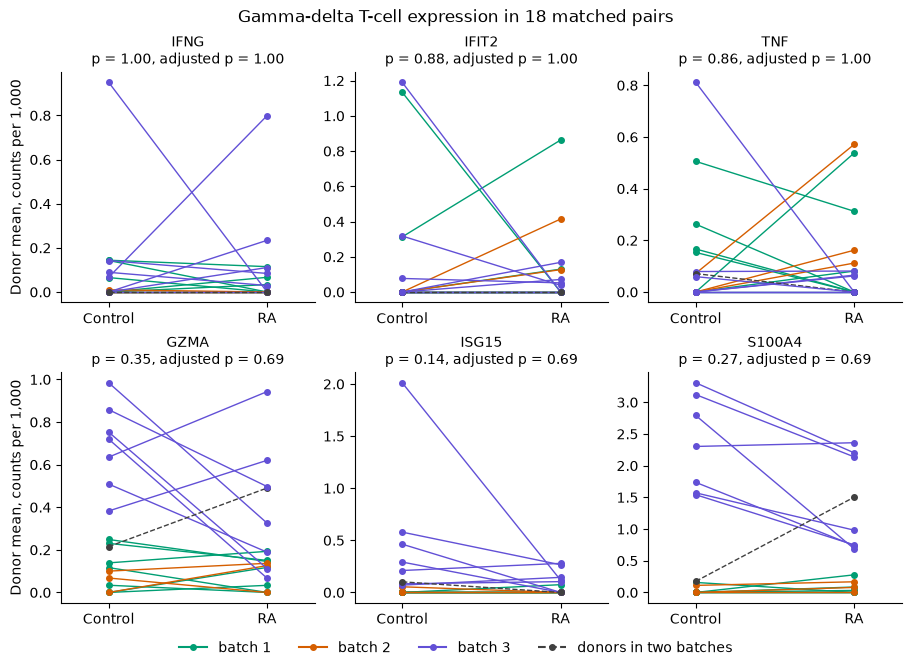

Started: 2026-11-12T17:12:37.332494Z | Wall time: 0.829 s

In [9]:
# Name the batch of each pair, or "two batches" when its donors were sequenced apart.
pair_batch = donor_design.groupby("pair_index_CW")["batch"].agg(
    lambda batches: str(batches.iloc[0]) if batches.nunique() == 1 else "two batches"
)
BATCH_STYLES = {
    "1": {"color": "#009E73", "linestyle": "-", "label": "batch 1"},
    "2": {"color": "#D55E00", "linestyle": "-", "label": "batch 2"},
    "3": {"color": "#6250D6", "linestyle": "-", "label": "batch 3"},
    "two batches": {
        "color": "0.25",
        "linestyle": "--",
        "label": "donors in two batches",
    },
}

# Draw each pair as a line from its control donor to its RA donor, one panel per gene.
figure, axes = plt.subplots(2, 3, figsize=(9, 6.6), layout="constrained")
for axis, gene in zip(axes.flat, panel):
    for pair, (control_mean, ra_mean) in paired_means[gene][GROUPS].iterrows():
        style = BATCH_STYLES[pair_batch[pair]]
        axis.plot(
            [0, 1],
            [control_mean, ra_mean],
            color=style["color"],
            linestyle=style["linestyle"],
            marker="o",
            markersize=4,
            linewidth=1,
        )
    p_value, adjusted = panel_table.loc[gene, ["p_value", "p_value_adjusted"]]
    axis.set_title(
        f"{gene}\np = {p_value:.2f}, adjusted p = {adjusted:.2f}", fontsize=10
    )
    axis.set_xticks([0, 1], ["Control", "RA"])
    axis.set_xlim(-0.3, 1.3)
    axis.spines[["top", "right"]].set_visible(False)
for axis in axes[:, 0]:
    axis.set_ylabel("Donor mean, counts per 1,000")
figure.legend(
    handles=[
        Line2D([], [], marker="o", markersize=4, **style)
        for style in BATCH_STYLES.values()
    ],
    loc="outside lower center",
    ncols=4,
    frameon=False,
)
figure.suptitle(f"Gamma-delta T-cell expression in {len(paired_means)} matched pairs")
plt.show()

S100A4, GZMA, and ISG15 reach high donor means only in batch 3 (violet), where most S100A4 and GZMA lines fall from control to RA. In batches 1 and 2, both donors of most pairs sit near zero for S100A4 and ISG15, while TNF runs higher there than in batch 3. Pair 22 (dashed) climbs from its batch-2 control to its batch-3 RA donor for S100A4 and GZMA, matching the gap between those batches rather than the fall seen in most batch-3 pairs. The table compares the batches:

In [10]:
# Compare the batches: the counts per selected cell, and the median donor mean of each gene.
selected_counts = pd.Series(
    np.asarray(ds.cells.fetch_all("RNA_nCounts"))[matched_gamma_delta.to_numpy()],
    index=cell_metadata.loc[matched_gamma_delta, "batch"].to_numpy(),
)
donors_by_batch = donor_means.join(donor_design["batch"]).groupby("batch")
pd.concat(
    [
        donors_by_batch.size().rename("donors"),
        selected_counts.groupby(level=0).median().rename("median counts per cell"),
        donors_by_batch.median().round(2),
    ],
    axis=1,
).rename_axis("batch")

,donors,median counts per cell,IFNG,IFIT2,TNF,GZMA,ISG15,S100A4
batch,,,,,,,,
1,14,311.0,0.00,0.0,0.04,0.12,0.00,0.00
2,7,245.0,0.00,0.0,0.07,0.10,0.00,0.08
3,15,817.5,0.07,0.0,0.00,0.51,0.14,1.74


Started: 2026-11-12T17:12:38.164629Z | Wall time: 0.030 s

Batch 3 differs from the other two batches in both depth and expression. Its gamma-delta T cells carry a median of 818 counts each, against 311 in batch 1 and 245 in batch 2, and its median donor has 1.74 S100A4 counts per 1,000, against 0.08 or less. Because 17 of the 18 pairs sit within one batch, their differences never compare donors across batches, but the batches do not weigh equally in the test: for S100A4, GZMA, and ISG15, the largest differences come from batch-3 pairs, which take the top ranks of the signed-rank test.

(pseudobulk_and_differential_expression)=

## Sum raw counts per donor for a count model

The signed-rank test covers six chosen genes and gives every donor mean the same weight, however many cells it averages. Testing all genes calls for a count model, such as the negative binomial models of DESeq2 and edgeR, fitted to raw counts with the donor as the replicate. With `aggr_type="sum"`, `compute_bulk` adds each gene's raw counts over a donor's selected cells instead of averaging scaled values, so `profiles` holds one pseudobulk count column per donor, and `columns["n_cells"]` gives the cells behind each column.

In [11]:
# Sum each gene's raw counts over each donor's selected cells.
pseudobulk = ds.compare.compute_bulk(
    "donor_id", cell_selection=cells, aggr_type="sum", feature_label="name"
)
bulk = pseudobulk.profiles
n_cells = pseudobulk.columns["n_cells"]
assert bulk.shape == (13_547, 36)

# Show the six genes' counts, and the cells behind them, for the donors of the first two pairs.
bulk.loc[panel, donor_design.index[:4]].T.join(n_cells)

,IFNG,IFIT2,TNF,GZMA,ISG15,S100A4,n_cells
donor_id,,,,,,,
Control01_1_A_M,0,5,1,0,0,0,15
RA01_1_A_M,1,0,0,1,0,2,78
Control03_1_C_F,0,0,0,0,0,0,30
RA03_1_C_F,0,0,0,2,0,0,10


Started: 2026-11-12T17:12:38.197934Z | Wall time: 2.003 s

The profiles hold one column for each of the 36 donors and cover 13,547 of the 21,648 genes, those with at least one count in the 1,386 cells. With a few hundred counts per cell, the six tested genes are rare even in donors with many cells: the 78 cells of RA01 hold 2 S100A4 counts, and the 30 cells of Control03 hold none of the six genes.

## Keep pairs with enough cells in both donors

A pseudobulk profile summed from a few cells measures its donor's gamma-delta T cells poorly, and the paired design needs both donors of a pair. A pair stays only when both of its donors have at least 20 cells. The bars show both donors of every pair, ordered by the smaller donor:

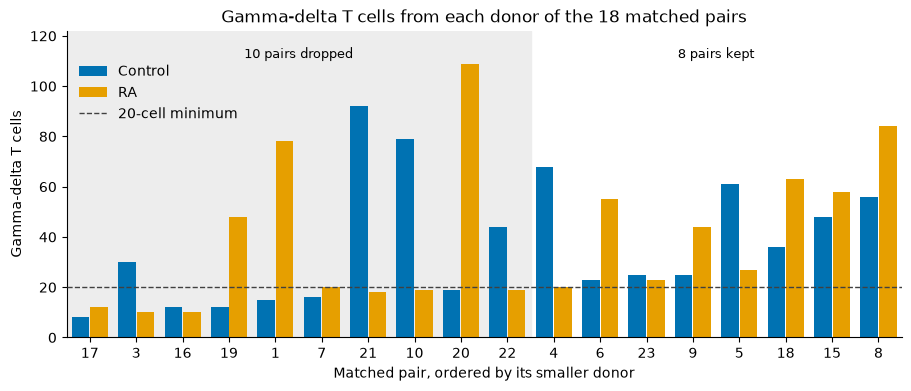

Started: 2026-11-12T17:12:40.204881Z | Wall time: 0.386 s

In [12]:
# Require at least 20 gamma-delta T cells from each donor of a pair.
min_cells_per_donor = 20

# Order the pairs by their smaller donor, which decides whether a pair stays.
pair_cells = donor_design.join(n_cells).pivot(
    index="pair_index_CW", columns="disease", values="n_cells"
)[GROUPS]
smaller_donor = pair_cells.min(axis=1).sort_values(kind="stable")
pair_cells = pair_cells.loc[smaller_donor.index]
kept_pairs = smaller_donor.index[smaller_donor >= min_cells_per_donor]
n_dropped = len(pair_cells) - len(kept_pairs)

# Plot both donors of every pair against the minimum, and shade the pairs it drops.
CONDITION_STYLES = {
    "normal": ("#0072B2", "Control"),
    "rheumatoid arthritis": ("#E69F00", "RA"),
}
figure, axis = plt.subplots(figsize=(9, 3.8), layout="constrained")
positions = np.arange(len(pair_cells))
axis.axvspan(-0.5, n_dropped - 0.5, color="0.93", zorder=0)
bars = [
    axis.bar(
        positions + offset,
        pair_cells[group],
        width=0.38,
        color=CONDITION_STYLES[group][0],
        label=CONDITION_STYLES[group][1],
        zorder=2,
    )
    for offset, group in zip((-0.2, 0.2), GROUPS)
]
minimum_line = axis.axhline(
    min_cells_per_donor,
    color="0.25",
    linestyle="--",
    linewidth=1,
    zorder=3,
    label=f"{min_cells_per_donor}-cell minimum",
)
top = pair_cells.to_numpy().max()
axis.text(
    (n_dropped - 1) / 2,
    top * 1.02,
    f"{n_dropped} pairs dropped",
    ha="center",
    fontsize=9,
)
axis.text(
    n_dropped + (len(kept_pairs) - 1) / 2,
    top * 1.02,
    f"{len(kept_pairs)} pairs kept",
    ha="center",
    fontsize=9,
)
axis.set_xticks(positions, pair_cells.index.astype(str))
axis.set(
    xlim=(-0.5, len(pair_cells) - 0.5),
    ylim=(0, top * 1.12),
    xlabel="Matched pair, ordered by its smaller donor",
    ylabel="Gamma-delta T cells",
    title=f"Gamma-delta T cells from each donor of the {len(pair_cells)} matched pairs",
)
axis.spines[["top", "right"]].set_visible(False)
axis.legend(
    handles=[*bars, minimum_line],
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(0, 0.93),
)
plt.show()

In [13]:
# Count the pairs that each minimum would keep, by the batch of the pair.
kept_by_minimum = pd.DataFrame(
    {
        minimum: (smaller_donor >= minimum).groupby(pair_batch).sum()
        for minimum in (0, 10, 15, 20, 25, 30)
    }
).reindex(list(BATCH_STYLES))
kept_by_minimum.loc["all"] = kept_by_minimum.sum()
kept_by_minimum.rename_axis(index="batch", columns="minimum cells per donor")

minimum cells per donor,0,10,15,20,25,30
batch,,,,,,
1,7,7,6,4,2,1
2,3,3,3,2,2,1
3,7,6,4,2,1,1
two batches,1,1,1,0,0,0
all,18,17,14,8,5,3


Started: 2026-11-12T17:12:40.593886Z | Wall time: 0.022 s

The 20-cell minimum drops 10 pairs and keeps 8. The table shows how fast pairs disappear as the minimum rises, from 18 without a minimum to 14 at 15 cells, 8 at 20, and 5 at 25. The minimum takes most from batch 3, where S100A4, GZMA, and ISG15 reach their highest levels: 2 of its 7 pairs remain at 20 cells. Set the minimum before fitting the model, because a minimum chosen after seeing the results makes the model's p-values too small. Restrict the design and the counts to the kept pairs, and drop the genes left without counts:

In [14]:
# Keep the design rows and count columns of the kept pairs, and drop genes without counts in them.
kept_design = donor_design[donor_design["pair_index_CW"].isin(kept_pairs)].join(n_cells)
kept_counts = bulk.loc[:, kept_design.index]
kept_counts = kept_counts.loc[kept_counts.sum(axis=1).gt(0)]
pd.Series(
    {
        "donors": len(kept_design),
        "matched pairs": kept_design["pair_index_CW"].nunique(),
        "cells": int(kept_design["n_cells"].sum()),
        "genes with counts": len(kept_counts),
        "pairs that span two batches": int(
            kept_design.groupby("pair_index_CW")["batch"].nunique().gt(1).sum()
        ),
    }
)

donors                            16
matched pairs                      8
cells                            716
genes with counts              11976
pairs that span two batches        0
dtype: int64

Started: 2026-11-12T17:12:40.618372Z | Wall time: 0.016 s

The 8 kept pairs hold 16 donors and 716 of the 1,386 cells, and 11,976 genes have at least one count in them. Pair 22 is gone, so both donors of every kept pair share a batch, and a pair term in the model also accounts for batch.

## Export counts and the donor design

Two CSV files hold the raw counts, one row per gene and one column per donor, and the donor design, one row per donor in the same order, with each donor's condition, pair, batch, and number of cells. Give a count-model method the raw integer counts, not normalized values: DESeq2 and edgeR estimate library sizes and dispersions from the counts themselves. Fit disease within pairs, with the design `~ pair_index_CW + disease` and `pair_index_CW` read as a factor. [CytePool](https://docs.nygen.io/CytePool/) tests pseudobulk profiles like these with limma, edgeR, or DESeq2.

In [15]:
# Write the raw counts and the donor design to CSV files in the working directory.
export_directory = Path("pseudobulk_exports")
export_directory.mkdir(exist_ok=True)
counts_csv = export_directory / "yd_t_cell_raw_counts.csv"
design_csv = export_directory / "yd_t_cell_donor_design.csv"
kept_counts.to_csv(counts_csv)
kept_design.rename_axis("donor_id").to_csv(design_csv)
pd.DataFrame(
    {
        "rows": [len(kept_counts), len(kept_design)],
        "columns": [kept_counts.shape[1], kept_design.shape[1]],
    },
    index=pd.Index([counts_csv.name, design_csv.name], name="file"),
)

,rows,columns
file,,
yd_t_cell_raw_counts.csv,11976,16
yd_t_cell_donor_design.csv,16,4


Started: 2026-11-12T17:12:40.638373Z | Wall time: 0.062 s